# 📘 3.2 Learning Data Noise and Overfitting

### When a curve fits the data too well

In Notebook 3.1, we introduced interpolation as a way to estimate values between measured data points.

However, there is an important catch:

> If the data contains noise, forcing a curve to pass exactly through every data point can make the curve learn the noise rather than the underlying engineering behaviour.

This is called **overfitting**.

In this notebook, we will explore overfitting using a synthetic aerospace example: estimating a lift coefficient curve from noisy wind-tunnel-like data.

The example is synthetic, which means we know the true underlying curve. In real engineering experiments, we usually do **not** know the true curve. That is why careful validation and engineering judgement are important.

### 🎯 Learning Objectives

By the end of this notebook, you should be able to:

* explain what measurement noise is;
* explain why exact interpolation can be inappropriate for noisy data;
* distinguish between **underfitting**, **reasonable fitting**, and **overfitting**;
* compare training error and validation error;
* explain why a model with very low training error may still be a poor engineering model;
* use plots and error metrics to identify possible overfitting.

### 🔗 Unit Learning Outcome Alignment

This notebook supports the following MMA3001 learning outcomes:

* **LO2:** Demonstrate effective use of numerical analysis and machine learning tools to develop defensible solutions to open-ended engineering problems.
* **LO3:** Apply appropriate mathematical and numerical techniques to solve common engineering problems, and evaluate program performance, error, stability and accuracy.

### 📚 Sources used in this notebook

The main technical ideas in this notebook are based on:

* Python Numerical Methods — Chapter 17: Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.00-Interpolation.html

* SciPy User Guide — Smoothing splines  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

* scikit-learn — Underfitting vs. Overfitting example  
  https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html

* scikit-learn source example — Underfitting vs. Overfitting  
  https://github.com/scikit-learn/scikit-learn/blob/main/examples/model_selection/plot_underfitting_overfitting.py

* NumPy documentation — Polynomial.fit  
  https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html

* NIST — Measurement uncertainty  
  https://www.nist.gov/itl/sed/topic-areas/measurement-uncertainty

## 📂 3.2.0 How to use this notebook

This is a **pre-work content notebook**. Run every code cell from top to bottom; no cell
requires editing or typed input.

The separate Week 3 workbook contains the activities to begin in Monday's workshop, continue in Wednesday's practical, and finish during revision at home.


## 📂 3.2.1 Why noisy data matters

A simple way to think about noisy experimental data is:

$$
y_i = f(x_i) + \epsilon_i
$$

where:

* $y_i$ is the measured value,
* $f(x_i)$ is the underlying physical relationship we wish we knew,
* $\epsilon_i$ is measurement noise or experimental variation.

In many teaching examples, we model noise as random:

$$
\epsilon_i \sim \mathcal{N}(0, \sigma^2)
$$

This means the noise is assumed to have mean zero and standard deviation $\sigma$.

### ⚠️ Point of note

This is only a modelling assumption.

Real engineering data can also contain:

* sensor bias,
* calibration errors,
* temperature drift,
* vibration effects,
* operator effects,
* finite resolution,
* data logging errors,
* changing test conditions.

Random noise may partly average out. Systematic errors usually do not.

## 📂 3.2.2 Interpolation vs fitting when data is noisy

In Notebook 3.1, we treated interpolation as useful when the data points are reliable.

For noisy data, this becomes dangerous.

> ### 📖 Definition: Exact interpolation
> Exact interpolation constructs a curve that passes through every data point.

> ### 📖 Definition: Fitting / approximation
> Fitting constructs a curve that captures the trend of the data, but does not necessarily pass through every point.

### Engineering interpretation

If each data point is a highly accurate table entry, interpolation may be appropriate.

If each data point is a noisy measurement, forcing the curve through every point may be misleading.

This is one of the key bridges between **interpolation** and **machine learning regression**.

## 📂 3.2.3 Underfitting and overfitting

When we fit a model to data, three broad outcomes are possible.

> ### 📖 Definition: Underfitting
> A model **underfits** when it is too simple to capture the important behaviour in the data.

> ### 📖 Definition: Overfitting
> A model **overfits** when it is so flexible that it captures noise or random variation in the training data.

> ### 📖 Definition: Generalisation
> A model **generalises** well when it performs well on new data, not just on the data used to build it.

### Useful engineering test

A model that works only on the data used to create it is not very useful.

A model should also perform reasonably on new measurements, new simulations, or new operating conditions that are within the same domain.

In [ ]:
from IPython.display import display
# Core imports for this notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.polynomial import Polynomial
from scipy.interpolate import make_interp_spline, make_smoothing_spline
from sklearn.metrics import mean_squared_error

pd.set_option("display.precision", 4)

## 📂 3.2.4 Synthetic aerospace example: lift coefficient data

We will create a synthetic wind-tunnel-like dataset.

The independent variable is angle of attack:

$$
\alpha
$$

The dependent variable is lift coefficient:

$$
C_L
$$

For a thin airfoil at small angles, lift coefficient often increases approximately linearly with angle of attack. At higher angles, real airfoils may experience nonlinear behaviour and stall.

Our synthetic curve is not a real airfoil dataset. It is designed to have a plausible engineering shape so that we can study noise and overfitting.

### Why use synthetic data?

Because we know the true curve.

That lets us directly compare:

* the noisy measurements,
* the fitted models,
* the true underlying relationship.

In a real experiment, the true curve is unknown.

In [ ]:
def true_lift_coefficient(alpha_deg):
    """
    Synthetic lift coefficient curve.

    This is not measured data. It is a teaching function designed to resemble
    a smooth lift curve with nonlinear behaviour at higher angle of attack.

    Parameters
    ----------
    alpha_deg : array-like
        Angle of attack in degrees.

    Returns
    -------
    array-like
        Synthetic lift coefficient.
    """
    alpha_deg = np.asarray(alpha_deg, dtype=float)

    alpha_rad = np.deg2rad(alpha_deg)
    linear_lift = 2 * np.pi * alpha_rad

    # Smooth saturation to avoid the curve growing forever.
    soft_saturation = 1.25 * np.tanh(linear_lift / 1.25)

    # Mild post-stall-like drop after 12 degrees.
    stall_drop = 0.018 * np.maximum(alpha_deg - 12.0, 0.0) ** 2

    return soft_saturation - stall_drop

In [ ]:
# Generate a noisy training dataset

rng = np.random.default_rng(42)

alpha_train = np.linspace(-4, 16, 17)
noise_std = 0.055

cl_true_train = true_lift_coefficient(alpha_train)
cl_measured = cl_true_train + rng.normal(0, noise_std, size=alpha_train.size)

training_data = pd.DataFrame({
    "alpha_deg": alpha_train,
    "cl_measured": cl_measured,
    "cl_true_for_teaching_only": cl_true_train
})

training_data

NameError: name 'np' is not defined

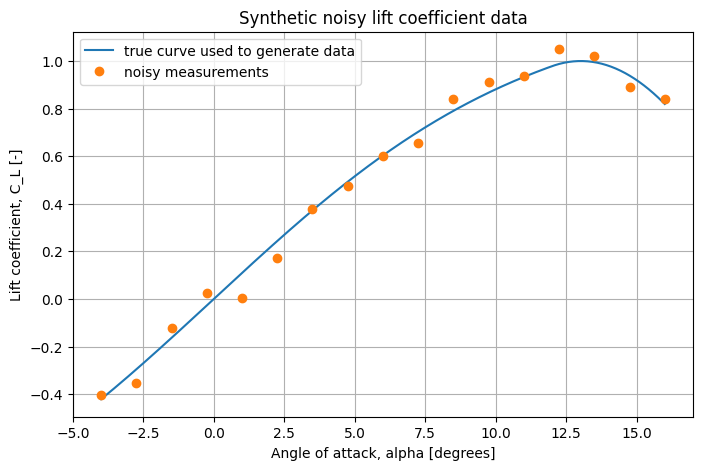

In [ ]:
# Plot the synthetic true curve and the noisy measurements

alpha_plot = np.linspace(-4, 16, 600)
cl_true_plot = true_lift_coefficient(alpha_plot)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(alpha_plot, cl_true_plot, label="true curve used to generate data")
ax.plot(alpha_train, cl_measured, "o", label="noisy measurements")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Synthetic noisy lift coefficient data")
ax.grid(True)
ax.legend()

plt.show()

> ### 🧩 Code Explanation
>
> The function `true_lift_coefficient` creates the underlying synthetic relationship.
>
> The measured values are generated using:
>
> $$
> C_{L,\text{measured}} = C_{L,\text{true}} + \epsilon
> $$
>
> where $\epsilon$ is random noise.
>
> In this teaching example, we can plot the true curve. In a real wind tunnel experiment, we would only have the measured points.

## 📂 3.2.5 Fitting polynomial models of different complexity

We will compare polynomial models of different degrees:

| Polynomial degree | Interpretation |
|---:|---|
| 1 | Very simple linear model |
| 3 | Moderately flexible model |
| 8 | Quite flexible model |
| 16 | Very flexible model that can pass almost exactly through 17 data points |

For 17 data points, a degree-16 polynomial has enough freedom to interpolate the training data.

That does not mean it is a good engineering model.

In [ ]:
def fit_polynomial_model(x, y, degree):
    """
    Fit a polynomial model using NumPy's Polynomial.fit.

    The domain is fixed to the data range to improve numerical conditioning.

    Parameters
    ----------
    x : array-like
        Independent variable.

    y : array-like
        Dependent variable.

    degree : int
        Polynomial degree.

    Returns
    -------
    numpy.polynomial.Polynomial
        Fitted polynomial model.
    """
    return Polynomial.fit(
        x,
        y,
        deg=degree,
        domain=[np.min(x), np.max(x)]
    )


degrees_to_compare = [1, 3, 8, 16]

polynomial_models = {}

for degree in degrees_to_compare:
    polynomial_models[degree] = fit_polynomial_model(
        alpha_train,
        cl_measured,
        degree
    )

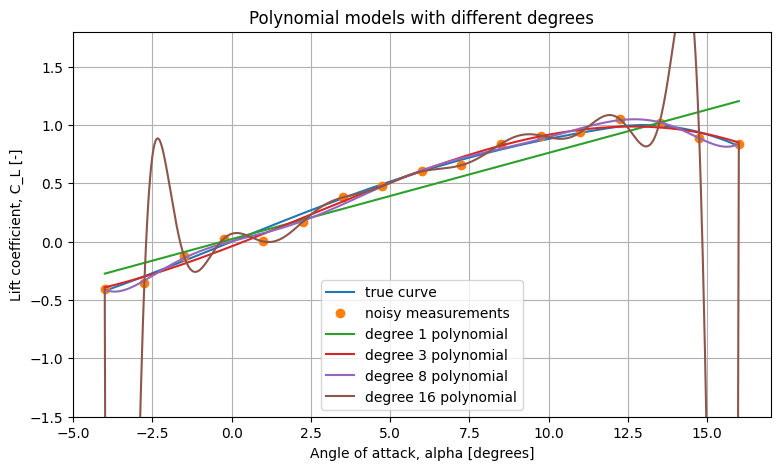

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_plot, cl_true_plot, label="true curve")
ax.plot(alpha_train, cl_measured, "o", label="noisy measurements")

for degree, model in polynomial_models.items():
    ax.plot(
        alpha_plot,
        model(alpha_plot),
        label=f"degree {degree} polynomial"
    )

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Polynomial models with different degrees")
ax.set_ylim(-1.5, 1.8)
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The degree-1 model is too simple. It cannot capture the nonlinear shape of the curve.

The degree-3 model captures the main trend reasonably well.

The degree-8 model is more flexible and still behaves reasonably for this dataset.

The degree-16 model fits the training points extremely closely, but it can oscillate strongly between points. This is a warning sign.

> ### ⚠️ Point of note
>
> A model that passes through every noisy data point can look mathematically impressive but be physically misleading.

## 📂 3.2.6 Training error vs validation error

A common mistake is judging a model only by how well it fits the data used to train it.

We will compare two errors:

> ### 📖 Definition: Training error
> Error measured on the data used to build the model.

> ### 📖 Definition: Validation error
> Error measured on separate data that was not used to build the model.

In engineering terms, validation data could come from:

* a repeated wind tunnel run,
* a separate simulation,
* a different sensor log,
* a held-out part of the experiment,
* a benchmark case.

A model with very low training error but high validation error is likely overfitting.

In [ ]:
def rmse(y_true, y_pred):
    """
    Calculate root mean squared error.

    RMSE has the same units as the quantity being predicted.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))


# Create a separate validation dataset.
# In a real experiment, this would be separate measured data.
# Here we generate it synthetically for teaching.

rng_validation = np.random.default_rng(99)

alpha_validation = np.linspace(-3.5, 15.5, 27)
cl_validation_true = true_lift_coefficient(alpha_validation)
cl_validation_measured = cl_validation_true + rng_validation.normal(
    0,
    noise_std,
    size=alpha_validation.size
)

validation_data = pd.DataFrame({
    "alpha_deg": alpha_validation,
    "cl_validation_measured": cl_validation_measured,
    "cl_validation_true_for_teaching_only": cl_validation_true
})

validation_data.head()

,alpha_deg,cl_validation_measured,cl_validation_true_for_teaching_only
0,-3.5000,-0.3677,-0.3722
1,-2.7692,-0.3234,-0.2978
2,-2.0385,-0.2184,-0.2212
3,-1.3077,-0.1050,-0.1428
4,-0.5769,-0.1598,-0.0632


In [ ]:
error_rows = []

for degree, model in polynomial_models.items():
    training_predictions = model(alpha_train)
    validation_predictions = model(alpha_validation)

    error_rows.append({
        "degree": degree,
        "training_RMSE": rmse(cl_measured, training_predictions),
        "validation_RMSE": rmse(cl_validation_measured, validation_predictions)
    })

error_table = pd.DataFrame(error_rows)

error_table

,degree,training_RMSE,validation_RMSE
0,1,1.4879e-01,0.1401
1,3,4.5764e-02,0.0531
2,8,3.3129e-02,0.0522
3,16,7.6043e-12,3.2088


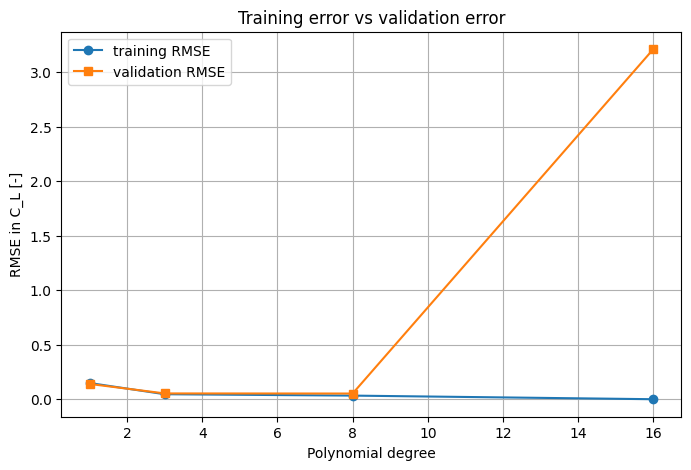

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    error_table["degree"],
    error_table["training_RMSE"],
    "o-",
    label="training RMSE"
)

ax.plot(
    error_table["degree"],
    error_table["validation_RMSE"],
    "s-",
    label="validation RMSE"
)

ax.set_xlabel("Polynomial degree")
ax.set_ylabel("RMSE in C_L [-]")
ax.set_title("Training error vs validation error")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The degree-16 polynomial should have almost zero training error.

That is expected because it has enough flexibility to pass through the training points.

However, its validation error is much larger.

This is the key symptom of overfitting:

$$
\text{training error is low, but validation error is high}
$$

### ⚠️ Engineering warning

A low training error does not prove that a model is accurate.

It may simply prove that the model is flexible enough to memorise the training data.

## 📂 3.2.7 Error as a function of model complexity

Rather than checking only four degrees, we can compute the training and validation error for many polynomial degrees.

This gives a practical way to see the underfitting-overfitting pattern.

The general pattern is often:

1. Low-degree models underfit.
2. Moderate-complexity models generalise better.
3. Very high-degree models overfit.

In [ ]:
all_degrees = np.arange(1, 17)

training_errors = []
validation_errors = []

for degree in all_degrees:
    model = fit_polynomial_model(alpha_train, cl_measured, degree)

    training_errors.append(
        rmse(cl_measured, model(alpha_train))
    )

    validation_errors.append(
        rmse(cl_validation_measured, model(alpha_validation))
    )

degree_error_table = pd.DataFrame({
    "degree": all_degrees,
    "training_RMSE": training_errors,
    "validation_RMSE": validation_errors
})

degree_error_table

,degree,training_RMSE,validation_RMSE
0,1,1.4879e-01,0.1401
1,2,7.8708e-02,0.0645
2,3,4.5764e-02,0.0531
3,4,4.2055e-02,0.0542
4,5,4.2010e-02,0.0547
5,6,4.1709e-02,0.0553
6,7,4.1619e-02,0.0546
7,8,3.3129e-02,0.0522
8,9,3.0274e-02,0.0558
9,10,2.5485e-02,0.0626


In [ ]:
best_row = degree_error_table.loc[
    degree_error_table["validation_RMSE"].idxmin()
]

best_degree = int(best_row["degree"])

print(f"Best degree by validation RMSE: {best_degree}")
print(f"Validation RMSE: {best_row['validation_RMSE']:.4f}")

Best degree by validation RMSE: 8
Validation RMSE: 0.0522


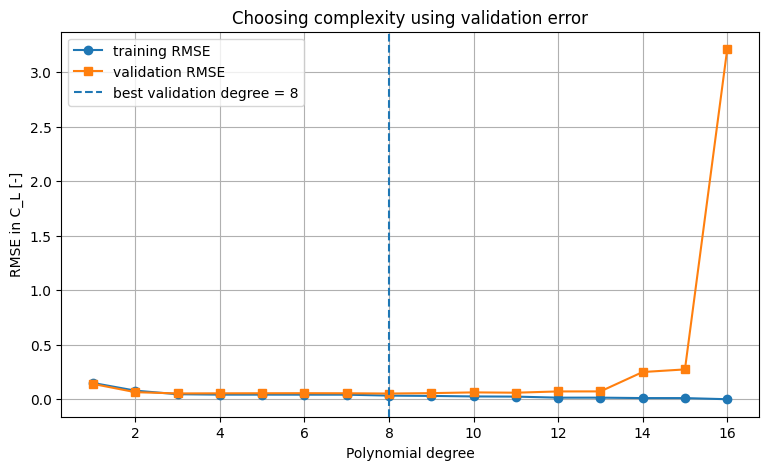

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    degree_error_table["degree"],
    degree_error_table["training_RMSE"],
    "o-",
    label="training RMSE"
)

ax.plot(
    degree_error_table["degree"],
    degree_error_table["validation_RMSE"],
    "s-",
    label="validation RMSE"
)

ax.axvline(best_degree, linestyle="--", label=f"best validation degree = {best_degree}")

ax.set_xlabel("Polynomial degree")
ax.set_ylabel("RMSE in C_L [-]")
ax.set_title("Choosing complexity using validation error")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 Interpretation

The best model is not necessarily the one with the lowest training error.

The best model is usually the one that balances:

* enough flexibility to capture the main trend;
* enough simplicity to avoid chasing noise;
* physical plausibility;
* acceptable validation performance.

In this example, the validation data helps identify a model complexity that generalises better than the exact high-degree interpolating polynomial.

> ### ⚠️ Point of note
>
> In real engineering work, validation data must be kept separate from model fitting.
>
> If you tune the model repeatedly using the same validation data, the validation data can become part of the modelling process. This issue will be revisited in Week 5.

## 📂 3.2.8 Exact interpolation of noisy data

Now let us compare two spline-based approaches:

1. **Exact cubic spline interpolation**  
   Passes through every noisy data point.

2. **Smoothing spline**  
   Approximates the data while penalising excessive curvature.

You do not need to understand spline details yet. Spline interpolation is covered in Notebook 3.4.

For now, focus on the engineering idea:

> If data is noisy, passing exactly through every point may not be desirable.

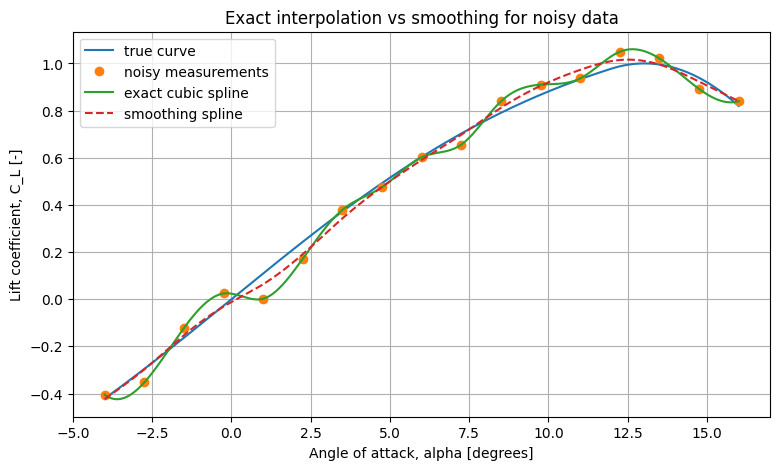

In [ ]:
# Exact cubic spline: passes through every measured data point.
exact_cubic_spline = make_interp_spline(alpha_train, cl_measured, k=3)

# Smoothing spline: approximates the data instead of forcing an exact pass.
# The parameter lam controls smoothness. Larger values produce smoother curves.
smoothing_spline = make_smoothing_spline(alpha_train, cl_measured, lam=1.0)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(alpha_plot, cl_true_plot, label="true curve")
ax.plot(alpha_train, cl_measured, "o", label="noisy measurements")
ax.plot(alpha_plot, exact_cubic_spline(alpha_plot), label="exact cubic spline")
ax.plot(alpha_plot, smoothing_spline(alpha_plot), "--", label="smoothing spline")

ax.set_xlabel("Angle of attack, alpha [degrees]")
ax.set_ylabel("Lift coefficient, C_L [-]")
ax.set_title("Exact interpolation vs smoothing for noisy data")
ax.grid(True)
ax.legend()

plt.show()

### 🧠 What should you notice?

The exact cubic spline passes through every noisy point.

The smoothing spline does not pass exactly through every point. Instead, it tries to capture the trend while avoiding unnecessary wiggles.

This is why SciPy's interpolation documentation distinguishes between exact interpolation and smoothing splines for noisy data.

### ⚠️ Engineering warning

Smoothing is not magic.

A smoothing method still requires choices, assumptions, and validation.

Too much smoothing can remove real physical behaviour. Too little smoothing can preserve noise.

## 📂 3.2.9 Worked extension — identify overfitting

Run the completed demonstration below.

Your task is to:

1. choose three polynomial degrees;
2. fit each polynomial;
3. compute training and validation RMSE;
4. decide which one is underfitting, which one is reasonable, and which one is overfitting.

Suggested degrees to try:

* 1
* 4
* 16

Then try your own choices.

In [ ]:
# Demonstration setting: Replace the ellipses with three polynomial degrees.

student_degrees = [
    1,
    4,
    16
]

student_rows = []

for degree in student_degrees:
    # Demonstration setting: fit a polynomial model of the chosen degree
    model = Polynomial.fit(alpha_train, cl_measured, deg=degree)

    # Demonstration setting: calculate predictions on training and validation data
    train_pred = model(alpha_train)
    validation_pred = model(alpha_validation)

    # Demonstration setting: calculate errors
    train_error = rmse(cl_measured, train_pred)
    validation_error = rmse(cl_validation_measured, validation_pred)

    student_rows.append({
        "degree": degree,
        "training_RMSE": train_error,
        "validation_RMSE": validation_error
    })

student_error_table = pd.DataFrame(student_rows)

student_error_table

,degree,training_RMSE,validation_RMSE
0,1,1.4879e-01,0.1401
1,4,4.2055e-02,0.0542
2,16,7.6043e-12,3.2088


### Reflection questions

Answer these in your own words.

1. Which model appears to underfit?
2. Which model appears to overfit?
3. Which model would you choose for an engineering estimate?
4. Did the model with the smallest training error also have the smallest validation error?
5. What does this tell you about trusting training error alone?

## 📂 3.2.10 Recommended resources

### Reading

* Python Numerical Methods — Chapter 17: Interpolation  
  https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.00-Interpolation.html

* SciPy User Guide — Smoothing splines  
  https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

* scikit-learn — Underfitting vs. Overfitting  
  https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html

* NumPy — Polynomial.fit  
  https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html

* NIST — Measurement uncertainty  
  https://www.nist.gov/itl/sed/topic-areas/measurement-uncertainty

### Videos

* StatQuest — Machine Learning Fundamentals: Bias and Variance  
  https://www.youtube.com/watch?v=EuBBz3bI-aA

* Underfitting & Overfitting — Explained  
  https://www.youtube.com/watch?v=o3DztvnfAJg

## 📂 3.2.11 A measurement model for noisy data

A useful engineering model is

$$y_i=f(x_i)+b(x_i)+\varepsilon_i$$

where \($f$\) is the underlying response, \($b$\) is systematic bias, and \($\varepsilon_i$\)
is random variation. Repeated measurements can reveal random variation, but repetition
does not automatically remove bias. Calibration, experimental design, and independent
reference measurements are needed to investigate systematic error.

Exact interpolation treats every observed \($y_i$\) as exact. That is defensible for a
reference table generated from an agreed function; it is often indefensible for laboratory
measurements with uncertainty. The correct target is usually the underlying response, not
every fluctuation in a particular sample.


## 📂 3.2.12 Connection to machine learning regression

Choosing a model from noisy data is also a machine learning regression problem. The aim is to capture the underlying engineering relationship without reproducing random variation in the observations. **Machine learning** workflows commonly use separate **training** and **validation** data:

- **Training data** is used to construct the model;
- **Validation data** is used to assess how well the model performs on unseen observations and to help choose its complexity.

Typically we would have the **ground truth** for both. Refering to highly accurate or known data.

More advanced workflows may also use cross-validation, regularisation, pipelines, and an independent test dataset. These ideas are introduced in Notebook 3.6, Interpolation in Machine Learning, and will be developed formally in Week 5, Machine Learning Regression.

For now, remember:

> A model should be judged by how well it represents the underlying engineering behaviour—not merely by how closely it passes through its training data.


## 📂 3.2.13 Engineering workflow and summary

When working with noisy engineering data:

1. Understand how the data was generated or measured.
2. Plot and inspect the data before selecting a model.
3. Begin with a simple model as a baseline.
4. Compare training performance with performance on separate validation data.
5. Examine the fitted curve and residuals, not only a single error value.
6. Check whether the result is physically plausible.
7. Report the data domain, assumptions, uncertainty, and likely failure modes.

The main lessons from this notebook are:

- experimental and simulated data may contain random variation and systematic bias;
- Exact interpolation is not always appropriate for noisy data;
- A model that is too simple may underfit;
- A model that follows random variation may overfit;
- Very low training error does not guarantee reliable predictions;
- Validation data provides evidence about performance on unseen observations;
- The most defensible model balances accuracy, simplicity, and physical plausibility.
- A curve can pass through every observation and still be a poor engineering model.

### 📚 Current software documentation checked

The implementation guidance in this notebook was checked against the current stable
documentation on 25 July 2026:

* SciPy 1.17 interpolation guide: https://docs.scipy.org/doc/scipy/tutorial/interpolate.html
* SciPy interpolation API: https://docs.scipy.org/doc/scipy/reference/interpolate.html
* scikit-learn 1.9 documentation (where used): https://scikit-learn.org/stable/


## 📚 References

1. Kong, Q., Siauw, T., Bayen, A. M., *Python Numerical Methods: A Guide for Engineers and Scientists*, Chapter 17: Interpolation.  
   https://pythonnumericalmethods.studentorg.berkeley.edu/notebooks/chapter17.00-Interpolation.html

2. SciPy User Guide, *Smoothing splines*.  
   https://docs.scipy.org/doc/scipy/tutorial/interpolate/smoothing_splines.html

3. scikit-learn Developers, *Underfitting vs. Overfitting*.  
   https://scikit-learn.org/stable/auto_examples/model_selection/plot_underfitting_overfitting.html

4. scikit-learn Developers, *Underfitting vs. Overfitting source example*.  
   https://github.com/scikit-learn/scikit-learn/blob/main/examples/model_selection/plot_underfitting_overfitting.py

5. NumPy Developers, *numpy.polynomial.polynomial.Polynomial.fit*.  
   https://numpy.org/doc/stable/reference/generated/numpy.polynomial.polynomial.Polynomial.fit.html

6. National Institute of Standards and Technology, *Measurement Uncertainty*.  
   https://www.nist.gov/itl/sed/topic-areas/measurement-uncertainty